# Model 3 — Factorized SupCon + Partial Unfreezing on ViT-B/16

**Model 3** starts from **Baseline 2 ViT**, the base model the team's deep-learning
models build on, and improves its representation in two stages:

1. **Stage 1: factorized supervised contrastive learning (SupCon).** The ViT-B/16
   backbone starts from Baseline 2 ViT's weights and is trained with two projection
   heads. One head pulls together images of the same crop, the other images of the same
   disease: $\mathcal{L} = \mathcal{L}^{crop}_{SupCon} + 1.5\,\mathcal{L}^{disease}_{SupCon}$.
   This is Model 2's Stage 1.
2. **Stage 2: heads plus partial unfreezing.** New crop and disease heads are trained
   with cross-entropy, while the **last two transformer blocks** (`blocks.10`,
   `blocks.11`) and the **final LayerNorm** are fine-tuned with a small learning rate
   (`1e-5`). The rest of the backbone stays frozen. This is what separates Model 3 from
   Model 2, whose Stage 2 trains only the heads on a frozen backbone.

Pairs are scored the same way as every baseline:
$\log p(\text{crop}) + \log p(\text{disease})$, plus a bias $b$ on pairs never seen in
training, with $b$ chosen on the pseudo-unseen dev split.

## Hypothesis

A frozen backbone with linear heads can underfit. Stage 1 shaped the features for a
contrastive objective, not for the crop and disease classifiers the composition score is
built from. Letting the top of the network adapt to those classifiers should raise seen
accuracy (Baseline 2 ViT: 70.5% seen top-1 at $b = 0$). Keeping the lower 10 blocks
frozen keeps most of the structure Stage 1 learned, so accuracy on unseen pairs should
not drop.

**Compared with Baseline 2 ViT**, as Lawrence's Model 5 does: after the final run, the
notebook scores Baseline 2 ViT and Model 3 with the same code on the same test images. It
shows how much Model 3 improves or degrades seen and unseen accuracy (top-1 and top-5),
the harmonic mean, AUC, unseen disease accuracy and the shortcut rate. Seen top-1 at
$b = 0$ and the harmonic mean should rise. Unseen disease accuracy, the shortcut rate and
AUC should not get worse.

## Starting weights without leakage

Baseline 2 ViT saved two models. Its **dev** model trained only on the dev training
subset, with the same 15 held-out pairs as every baseline. Its **final** model trained on
all 8,000 training images. Model 3's dev run starts from the dev model and its final run
from the final model. Starting the dev run from the final model would leak: that model
has already trained on the dev validation images, so the dev bias and epoch would be
chosen on images it has seen. The notebook refuses that combination, and it checks that
the dev model's held-out pairs match.

## Settings (team blueprint, same as Model 2)

| | Value |
|---|---|
| Stage 1 | SupCon $\tau = 0.07$, $\lambda_{disease} = 1.5$, batch 8 images × 2 views, 10 epochs, lr `3e-5` backbone / `3e-4` projectors, 1-epoch warm-up + cosine |
| Stage 2 | up to 10 epochs (best dev epoch kept), batch 16, heads lr `1e-3` (weight decay `1e-4`), blocks 10–11 + final norm lr `1e-5` (weight decay 0.05), label smoothing 0.1 |
| Trainable in Stage 2 | about 14.4 M parameters (Model 2: 0.18 M) |
| Dev split | 15 pseudo-unseen pairs, 10% val-seen, seed 42, the same as every baseline |

Setting `unfreeze_blocks=0` turns Stage 2 back into Model 2's, which is a useful sanity
check.

## How to run (Colab, T4 GPU)

1. Ask Lawrence to share his `outputs/baseline2_multitask_vit` folder, which holds
   `dev/best.pt`, `dev/summary.json` and `final/best.pt`. In Drive, open **Shared with
   me**, right-click the folder, choose **Organize → Add shortcut**, and place the
   shortcut in `MyDrive/COS30082/outputs/`. The notebook then finds both checkpoints by
   itself. Otherwise, set `b2_dev_ckpt` and `b2_final_ckpt`.
2. Upload this notebook to Drive, open it in Colab, pick **Runtime → Change runtime type
   → T4 GPU**, and press **Run all**. Dev runs, then final, in about 2 hours in total.
3. If Colab disconnects, press **Run all** again. Finished stages are reloaded and Stage 1
   resumes from its last epoch.

Images come from `MyDrive/COS30082/cache/dpd_small_320.zip` (made by the Baseline 1
notebook), or from an extracted `DPD_Small` folder on Drive. Outputs go to
`MyDrive/COS30082/outputs/model3_supcon_partial_unfreeze/runs/`. They include
`model3_eval.pt` and `metrics.json` for the team evaluator. Locally, the notebook runs
from inside the repository like Model 2. Optionally, `stage1_dev_ckpt` and
`stage1_final_ckpt` load Stage 1 weights from another run instead of training them.

In [15]:
import os, sys, json, math, random, time, subprocess, importlib.util, hashlib, shutil
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

def find_repo_root(start):
    for p in [start, *start.parents]:
        if (p / 'DPD_Small').exists() and (p / 'Baseline1').exists():
            return p
    raise FileNotFoundError('Run locally from inside the repository (it needs DPD_Small/ and Baseline1/), '
                            'or open this notebook in Colab.')

if not IN_COLAB:
    REPO_ROOT = find_repo_root(Path.cwd())
    os.environ.setdefault('TORCH_HOME', str(REPO_ROOT / '.runtime' / 'torch'))
    os.environ.setdefault('HF_HOME', str(REPO_ROOT / '.runtime' / 'huggingface'))

for _pkg in ('timm', 'tqdm'):
    if importlib.util.find_spec(_pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm
import timm

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'
print('device:', DEVICE, torch.cuda.get_device_name(0) if AMP else '(CPU: in Colab use Runtime > Change runtime type > T4 GPU)')

VARIANT = 'model3_supcon_partial_unfreeze'

CFG = dict(
    run_mode='dev',                 # 'dev' then 'final'
    auto_final=True,                # after dev, switch to final in the same Run All
    smoke=False,                    # True = 1-epoch subset smoke test
    # --- Stage 1 starting weights: Baseline 2 ViT, the base model for the team's deep-learning models ---
    init_from='b2',                 # 'b2' = Baseline 2 ViT weights | 'imagenet' = ImageNet weights
    b2_dev_ckpt=None,               # None = MyDrive/COS30082/outputs/baseline2_multitask_vit/dev/best.pt
    b2_final_ckpt=None,             # None = MyDrive/COS30082/outputs/baseline2_multitask_vit/final/best.pt
    b2_init_ckpt=None,              # filled in automatically for each run (dev or final) from the two paths above
    # --- optional: load Stage 1 weights from another run instead of training them ---
    stage1_dev_ckpt=None,
    stage1_final_ckpt=None,
    # --- identical to Model 2 ---
    backbone='vit_base_patch16_224',
    pretrained=True,
    img_size=224,
    stage1_epochs=10,
    stage2_epochs=10,
    stage1_batch_size=8,
    stage2_batch_size=16,
    eval_batch_size=16,
    num_workers=2 if IN_COLAB else 0,
    lr_backbone=3e-5,
    lr_projection=3e-4,
    lr_head=1e-3,
    weight_decay=0.05,
    head_weight_decay=1e-4,
    supcon_temp=0.07,
    lambda_disease=1.5,
    label_smoothing=0.1,
    proj_hidden=256,
    proj_dim=128,
    drop_rate=0.0,
    num_holdout_pairs=15,
    val_frac=0.1,
    seed=42,
    # --- Model 3 only: Stage 2 partial unfreezing ---
    unfreeze_blocks=2,              # last 2 transformer blocks (blocks.10, blocks.11) + final norm; 0 = Model 2
    lr_unfrozen=1e-5,
    unfrozen_weight_decay=0.05,     # the weight decay the backbone had in Stage 1
    # --- Colab data and output locations (ignored when running locally) ---
    drive_root='/content/drive/MyDrive/COS30082',
    dataset_dir=None,               # optional: Drive folder holding the 3 CSVs + DPD_Small_dataset/
    local_root='/content',          # fast local disk for the image cache
)
if os.environ.get('M3_CFG'):        # local CPU tests only
    CFG.update(json.loads(os.environ['M3_CFG']))

assert CFG['init_from'] in ('b2', 'imagenet'), "init_from must be 'b2' or 'imagenet'"
assert CFG['run_mode'] in ('dev', 'final')
if CFG['smoke']:
    assert CFG['run_mode'] == 'dev', 'smoke mode is dev-only'
    CFG.update(
        stage1_epochs=1,
        stage2_epochs=1,
        stage1_batch_size=4,
        stage2_batch_size=4,
        num_holdout_pairs=3,
        stage1_dev_ckpt=None,       # a real Stage 1 was not trained on the smoke split
        stage1_final_ckpt=None,
    )

RUN_ROOT = (Path(CFG['drive_root']) / 'outputs' / VARIANT) if IN_COLAB else (REPO_ROOT / 'DeepLearning' / 'Model 3')
OUT_DIR = RUN_ROOT / ('runs_smoke' if CFG['smoke'] else 'runs')
OUT_DIR.mkdir(parents=True, exist_ok=True)
DEV_SUMMARY = OUT_DIR / 'dev_summary.json'

seed_everything(CFG['seed'])
print(json.dumps({k: str(v) if isinstance(v, Path) else v for k, v in CFG.items()}, indent=2))
print('out_dir:', OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda Tesla T4
{
  "run_mode": "dev",
  "auto_final": true,
  "smoke": false,
  "init_from": "b2",
  "b2_dev_ckpt": null,
  "b2_final_ckpt": null,
  "b2_init_ckpt": null,
  "stage1_dev_ckpt": null,
  "stage1_final_ckpt": null,
  "backbone": "vit_base_patch16_224",
  "pretrained": true,
  "img_size": 224,
  "stage1_epochs": 10,
  "stage2_epochs": 10,
  "stage1_batch_size": 8,
  "stage2_batch_size": 16,
  "eval_batch_size": 16,
  "num_workers": 2,
  "lr_backbone": 3e-05,
  "lr_projection": 0.0003,
  "lr_head": 0.001,
  "weight_decay": 0.05,
  "head_weight_decay": 0.0001,
  "supcon_temp": 0.07,
  "lambda_disease": 1.5,
  "label_smoothing": 0.1,
  "proj_hidden": 256,
  "proj_dim": 128,
  "drop_rate": 0.0,
  "num_holdout_pairs": 15,
  "val_frac": 0.1,
  "seed": 42,
  "unfreeze_blocks": 2,
  "lr_unfrozen": 1e-05,
  "unfrozen_weight_decay": 0.05,
  "drive_roo

## Data

Images come from the team's 320 px cache: each image was resized once so its shorter side
is 320 px, with the EXIF orientation applied. That is the same cache the Baseline 1
notebook made. On Colab the zip is copied from Drive to the fast local disk and unpacked
there. Every image the CSVs list is then checked. If any are missing, or there is no
zip, they are resized from the extracted `DPD_Small` folder on Drive, and the complete
zip is saved back for next time. Locally it uses Model 2's layout:
`DPD_Small/` holds the CSVs and `.runtime/dpd_small_320/` holds the images.

In [16]:
from concurrent.futures import ThreadPoolExecutor

CSV_NAMES = ['DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_test_unseen.csv']
CACHE_NAME = 'dpd_small_320'

def has_csvs(path):
    return path is not None and all((Path(path) / n).is_file() for n in CSV_NAMES)

def is_dataset_folder(path):
    return has_csvs(path) and (Path(path) / 'DPD_Small_dataset').is_dir()

def find_extracted_folder():
    """An extracted DPD_Small folder on Drive (3 CSVs + DPD_Small_dataset/), or None."""
    if CFG['dataset_dir']:
        if not is_dataset_folder(CFG['dataset_dir']):
            raise FileNotFoundError(f"dataset_dir={CFG['dataset_dir']!r} must hold {CSV_NAMES} and DPD_Small_dataset/")
        return Path(CFG['dataset_dir'])
    my_drive = Path(CFG['drive_root']).parent
    candidates = [Path(CFG['drive_root']) / 'DPD_Small', Path(CFG['drive_root'])]
    for pattern in ('*', '*/*'):    # up to two folders below MyDrive
        candidates += sorted(p.parent for p in my_drive.glob(f'{pattern}/{CSV_NAMES[0]}'))
    return next((c for c in candidates if is_dataset_folder(c)), None)

# Phone photos store their rotation in an EXIF tag. ImageOps.exif_transpose crashes on some
# DPD images with malformed EXIF, so only the orientation tag is read.
ORIENTATION_FIX = {2: Image.Transpose.FLIP_LEFT_RIGHT, 3: Image.Transpose.ROTATE_180,
                   4: Image.Transpose.FLIP_TOP_BOTTOM, 5: Image.Transpose.TRANSPOSE,
                   6: Image.Transpose.ROTATE_270, 7: Image.Transpose.TRANSVERSE,
                   8: Image.Transpose.ROTATE_90}

def load_upright(path):
    with Image.open(path) as im:
        try:
            orientation = im.getexif().get(0x0112, 1)
        except Exception:
            orientation = 1
        im = im.convert('RGB')
    if orientation in ORIENTATION_FIX:
        im = im.transpose(ORIENTATION_FIX[orientation])
    im.info = {}
    return im

def build_cache(src_dir, cache_dir):
    """Resize every image listed in the CSVs to a 320 px shorter side; files already cached are kept."""
    src_dir, cache_dir = Path(src_dir), Path(cache_dir)
    dst_dir = cache_dir / 'DPD_Small_dataset'
    dst_dir.mkdir(parents=True, exist_ok=True)
    for n in CSV_NAMES:
        shutil.copy(src_dir / n, cache_dir / n)
    names = pd.concat([pd.read_csv(src_dir / n, header=None)[0] for n in CSV_NAMES]).unique()
    todo = [n for n in names if not (dst_dir / n).exists()]
    if todo:
        src_images = src_dir / 'DPD_Small_dataset'
        available = set(os.listdir(src_images)) if src_images.is_dir() else set()
        missing = [n for n in todo if n not in available]
        if missing:
            raise FileNotFoundError(f'{len(missing)} of {len(names)} images listed in the CSVs are missing from '
                                    f'{src_images} (e.g. {missing[:3]}). Finish the upload and run again.')

        def resize_one(name):
            dst = dst_dir / name
            dst.parent.mkdir(parents=True, exist_ok=True)
            im = load_upright(src_images / name)
            scale = 320 / min(im.size)
            if scale < 1:
                im = im.resize((round(im.width * scale), round(im.height * scale)), Image.BICUBIC)
            im.save(dst, quality=95)

        print(f'resizing {len(todo)} images (one-off) ...', flush=True)
        with ThreadPoolExecutor(16) as pool:
            for i, _ in enumerate(pool.map(resize_one, todo), 1):
                if i % 1000 == 0:
                    print(f'  {i}/{len(todo)}', flush=True)
    (cache_dir / '.complete').touch()

def cache_gaps(csv_dir, cache_dir):
    """(missing image names, number listed): images the CSVs list that the cache does not hold."""
    names = pd.concat([pd.read_csv(Path(csv_dir) / n, header=None)[0] for n in CSV_NAMES]).unique()
    img_dir = Path(cache_dir) / 'DPD_Small_dataset'
    return [n for n in names if not (img_dir / n).is_file()], len(names)

if IN_COLAB:
    CACHE_DIR = Path(CFG['local_root']) / CACHE_NAME
    CACHE_ZIP = Path(CFG['drive_root']) / 'cache' / f'{CACHE_NAME}.zip'   # made by Baseline 1, shared by the team
    if not (CACHE_DIR / '.complete').exists() and CACHE_ZIP.exists():
        local_zip = Path(CFG['local_root']) / CACHE_ZIP.name
        local_zip.parent.mkdir(parents=True, exist_ok=True)
        print('copying the resized dataset from Drive:', CACHE_ZIP, flush=True)
        shutil.copyfile(CACHE_ZIP, local_zip)    # one sequential read; unzipping straight from Drive can drop files
        print('unpacking the resized dataset on the local disk ...', flush=True)
        shutil.unpack_archive(local_zip, CFG['local_root'])
        local_zip.unlink()
    # Never trust the cache blindly: every image the CSVs list must be there.
    gaps = cache_gaps(CACHE_DIR, CACHE_DIR) if has_csvs(CACHE_DIR) else None
    if gaps is None or gaps[0]:
        src = find_extracted_folder()
        if src is None and gaps is None:
            raise FileNotFoundError(
                f'No DPD-Small data found. Looked for {CACHE_ZIP} and for a DPD_Small folder (3 CSVs + '
                f'DPD_Small_dataset/) up to two levels below {Path(CFG["drive_root"]).parent}. '
                'Set dataset_dir in the config to that folder.')
        if src is None:
            raise FileNotFoundError(
                f'{len(gaps[0])} of {gaps[1]} images are missing from the unpacked cache {CACHE_ZIP} '
                f'(e.g. {gaps[0][:3]}), and no extracted DPD_Small folder was found on Drive to rebuild them. '
                'Set dataset_dir in the config to that folder.')
        if gaps is None:
            print('building the resized cache from', src, flush=True)
        else:
            print(f'{len(gaps[0])} of {gaps[1]} images are missing from the cache; resizing them from {src}', flush=True)
        build_cache(src, CACHE_DIR)
        try:
            CACHE_ZIP.parent.mkdir(parents=True, exist_ok=True)
            shutil.make_archive(str(CACHE_ZIP)[:-len('.zip')], 'zip', CFG['local_root'], CACHE_NAME)
            print('saved the complete resized dataset to Drive for next time:', CACHE_ZIP)
        except OSError as e:
            print('could not save the cache zip to Drive (training can still go ahead):', e)
    DATA_DIR = CACHE_DIR                       # the cache holds copies of the 3 CSVs
else:
    DATA_DIR = REPO_ROOT / 'DPD_Small'         # Model 2's local layout
    CACHE_DIR = REPO_ROOT / '.runtime' / CACHE_NAME
    if not (CACHE_DIR / '.complete').exists() or cache_gaps(DATA_DIR, CACHE_DIR)[0]:
        build_cache(DATA_DIR, CACHE_DIR)
IMAGE_DIR = CACHE_DIR / 'DPD_Small_dataset'
assert has_csvs(DATA_DIR) and IMAGE_DIR.is_dir(), f'data not ready: {DATA_DIR}, {IMAGE_DIR}'
missing, n_listed = cache_gaps(DATA_DIR, CACHE_DIR)
assert not missing, f'{len(missing)} of {n_listed} images still missing from {IMAGE_DIR}, e.g. {missing[:3]}'
print(f'cache check: all {n_listed} images listed in the CSVs are present')
print('CSV folder:', DATA_DIR, '| image folder:', IMAGE_DIR)

cache check: all 11448 images listed in the CSVs are present
CSV folder: /content/dpd_small_320 | image folder: /content/dpd_small_320/DPD_Small_dataset


## Metadata and composition mappings

The DPD metadata CSVs have no header and seven columns:
`file, crop_id, disease_id, composition_id, crop_name, disease_name, composition_name`.
The notebook rebuilds the three label spaces directly from the data so that the
55 crop classes, 175 disease classes, and 333 seen compositions are aligned with
the image folders and with the Baseline 2 checkpoints.

A **composition** is a specific crop–disease pair. The training set contains 323
seen compositions; the unseen test set contains 10 held-out compositions. This is
the core difficulty of the assignment: both the crop and the disease may have
been seen during training, but their *combination* has not. The mappings
`COMP_CROP` and `COMP_DIS` convert a composition index into its crop/disease
indices, and `NOVEL_MASK` marks which of the 333 compositions are unseen. The
final evaluation builds `NOVEL_MASK` from `train_df`, so no test label leaks into
calibration.

In [17]:
COLS = ['file', 'crop', 'disease', 'comp', 'crop_name', 'disease_name', 'comp_name']

def read_split(path):
    return pd.read_csv(path, header=None, names=COLS)

train_df = read_split(DATA_DIR / 'DPD_Small_train.csv')
test_seen_df = read_split(DATA_DIR / 'DPD_Small_test_seen.csv')
test_unseen_df = read_split(DATA_DIR / 'DPD_Small_test_unseen.csv')
all_df = pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True)

assert (all_df.groupby('comp')[['crop', 'disease']].nunique() == 1).all().all()
comps = (all_df.drop_duplicates('comp').sort_values('comp')
         [['comp', 'crop', 'disease', 'crop_name', 'disease_name', 'comp_name']]
         .reset_index(drop=True))
assert comps['comp'].tolist() == list(range(len(comps)))

NUM_CROPS = int(all_df['crop'].max()) + 1
NUM_DISEASES = int(all_df['disease'].max()) + 1
NUM_COMPS = len(comps)
COMP_CROP = torch.tensor(comps['crop'].values)
COMP_DIS = torch.tensor(comps['disease'].values)
COMP_NAMES = comps['comp_name'].tolist()
CROP_NAMES = all_df.drop_duplicates('crop').set_index('crop')['crop_name'].sort_index().tolist()
DISEASE_NAMES = all_df.drop_duplicates('disease').set_index('disease')['disease_name'].sort_index().tolist()

TRAIN_COMPS = set(train_df['comp'])
UNSEEN_COMPS = set(test_unseen_df['comp'])
assert not TRAIN_COMPS & UNSEEN_COMPS

hasher = hashlib.sha256()
for path in (DATA_DIR / 'DPD_Small_train.csv', DATA_DIR / 'DPD_Small_test_seen.csv', DATA_DIR / 'DPD_Small_test_unseen.csv'):
    with open(path, 'rb') as f:
        hasher.update(f.read())
data_fingerprint = hasher.hexdigest()

print(f'train {len(train_df)} | test-seen {len(test_seen_df)} | test-unseen {len(test_unseen_df)}')
print(f'crops {NUM_CROPS} | diseases {NUM_DISEASES} | compositions {NUM_COMPS} '
      f'(seen {len(TRAIN_COMPS)}, unseen {len(UNSEEN_COMPS)})')
print('data fingerprint:', data_fingerprint[:16])

train 8000 | test-seen 2000 | test-unseen 1448
crops 55 | diseases 175 | compositions 333 (seen 323, unseen 10)
data fingerprint: ef9de7a92352f771


## Pseudo-unseen dev split

Test-unseen labels cannot be used to choose an epoch or a novelty bias, so the
notebook creates a **pseudo-unseen** validation problem from the training set.
Fifteen seen compositions are held out as `val_unseen`; 10% of the remaining
images become `val_seen`; the rest is `fit_df`. Stage 1 and Stage 2 fit only on
`fit_df`. This mirrors the real evaluation: the model sees the individual crops
and diseases during training, but not the held-out composition pairs.

The split is controlled by `CFG['dev_holdout_pairs']`, `CFG['val_frac']`, and
`CFG['seed']`. The same seed is used every run, so the dev comparison is stable.
`val_seen` and `val_unseen` are used for epoch selection and bias calibration;
the final run does **not** use them for training. The test set is untouched until
the final evaluation cell.

**Important:** the held-out pairs are unseen *compositions*, not unseen crops or
unseen diseases. This matches the assignment's unseen-composition setting and is
why the 10% dev-seen split still covers the same crop/disease classes.

In [18]:
def make_dev_split(df, k, val_frac, seed):
    rng = np.random.RandomState(seed)
    pairs = df.groupby('comp').agg(crop=('crop', 'first'), disease=('disease', 'first'))
    remaining, holdout = pairs.copy(), []
    for c in rng.permutation(pairs.index.values):
        if len(holdout) == k:
            break
        rest = remaining.drop(c)
        if (rest['crop'] == pairs.at[c, 'crop']).any() and (rest['disease'] == pairs.at[c, 'disease']).any():
            holdout.append(int(c))
            remaining = rest
    val_unseen = df[df['comp'].isin(holdout)]
    rest_df = df[~df['comp'].isin(holdout)]
    val_idx = []
    for _, g in rest_df.groupby('comp'):
        n_val = int(len(g) * val_frac)
        if n_val:
            val_idx += g.sample(n_val, random_state=seed).index.tolist()
    val_seen = rest_df.loc[val_idx]
    fit = rest_df.drop(index=val_idx)
    return fit.reset_index(drop=True), val_seen.reset_index(drop=True), val_unseen.reset_index(drop=True), sorted(holdout)

if CFG['run_mode'] == 'dev':
    fit_df, val_seen_df, val_unseen_df, HOLDOUT = make_dev_split(
        train_df, CFG['num_holdout_pairs'], CFG['val_frac'], CFG['seed']
    )
else:
    fit_df, val_seen_df, val_unseen_df, HOLDOUT = train_df.copy(), None, None, []

if CFG['smoke']:
    fit_df = fit_df.sample(n=min(256, len(fit_df)), random_state=CFG['seed']).reset_index(drop=True)
    val_seen_df = val_seen_df.sample(n=min(64, len(val_seen_df)), random_state=CFG['seed']).reset_index(drop=True)
    val_unseen_df = val_unseen_df.sample(n=min(64, len(val_unseen_df)), random_state=CFG['seed']).reset_index(drop=True)

assert len(fit_df) > 0
if CFG['run_mode'] == 'dev':
    assert len(val_seen_df) > 0 and len(val_unseen_df) > 0, 'Dev split must contain seen and pseudo-unseen images'

FIT_COMPS = sorted(set(fit_df['comp']))
NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
NOVEL_MASK[FIT_COMPS] = False

print(f'fit {len(fit_df)} | val-seen {0 if val_seen_df is None else len(val_seen_df)} | '
      f'val-unseen {0 if val_unseen_df is None else len(val_unseen_df)} | holdout {len(HOLDOUT)}')
print('holdout pairs:', [COMP_NAMES[c] for c in HOLDOUT])

fit 6956 | val-seen 638 | val-unseen 406 | holdout 15
holdout pairs: ['apple_healthy', 'blackgram_powdery_mildew', 'broccoli_alternaria_leaf_spot', 'broccoli_ring_spot', 'cauliflower_bacterial_spot', 'cauliflower_black_rot', 'cherry_spot', 'citrus_black_spot', 'cucumber_angular_leaf_spot', 'paddy_bacterial_blight', 'papaya_curl', 'plum_aphis_spp', 'sugarcane_smut', 'tea_healthy', 'tomato_mosaic_virus']


### Same data and split as Model 2

The two values below are copied from Model 2's `runs/dev_summary.json`. If both print
**yes**, Model 3 reads byte-identical CSVs and holds out the same 15 pseudo-unseen pairs,
which are also the pairs every baseline used.

In [19]:
MODEL2_DATA_FINGERPRINT = 'ef9de7a92352f771b541a68c703ad7d32eec5434e458a5cb94003080a9667fe9'
MODEL2_HOLDOUT_PAIRS = [
    'apple_healthy', 'blackgram_powdery_mildew', 'broccoli_alternaria_leaf_spot', 'broccoli_ring_spot',
    'cauliflower_bacterial_spot', 'cauliflower_black_rot', 'cherry_spot', 'citrus_black_spot',
    'cucumber_angular_leaf_spot', 'paddy_bacterial_blight', 'papaya_curl', 'plum_aphis_spp',
    'sugarcane_smut', 'tea_healthy', 'tomato_mosaic_virus',
]
print('CSV files identical to Model 2:', 'yes' if data_fingerprint == MODEL2_DATA_FINGERPRINT else 'NO')
if CFG['run_mode'] == 'dev' and not CFG['smoke']:
    same_pairs = [COMP_NAMES[c] for c in HOLDOUT] == MODEL2_HOLDOUT_PAIRS
    print('pseudo-unseen pairs identical to Model 2 and the baselines:', 'yes' if same_pairs else 'NO')

CSV files identical to Model 2: yes
pseudo-unseen pairs identical to Model 2 and the baselines: yes


## Two-view transforms and loaders

Supervised contrastive learning needs at least two views of the same image so
that the loss can pull the two views together while pushing other samples away.
Stage 1 therefore uses a **two-view transform**: two independent random crops
(scale 0.6–1.0), horizontal and vertical flips, mild rotation, color jitter, and
ImageNet normalization. The two views are returned as a tuple; each image
contributes two 224×224 tensors to the contrastive batch.

Stage 2 uses a single-view B2-style augmentation because it only trains linear
heads. Evaluation is deterministic and matches B2 v2: resize to 224×224 with
bilinear interpolation, then normalize. The loader uses `drop_last=True` in
Stage 1 so every contrastive batch has complete positive sets; Stage 2 and
evaluation keep all images.

`CFG['stage1_batch_size']=8` means 8 source images × 2 views = 16 ViT inputs per
step. On a 6 GB laptop GPU this is the main memory risk; lower it to 4 if
PyTorch reports an out-of-memory error. Gradient accumulation would not enlarge
the SupCon positive set, so it is not used as a substitute for batch size.

In [20]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
S = CFG['img_size']

supcon_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.6, 1.0), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20, fill=128),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

stage2_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.8, 1.0), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15, fill=128),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_tf = transforms.Compose([
    transforms.Resize((S, S), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class TwoViewTransform:
    def __init__(self, base_tf):
        self.base_tf = base_tf

    def __call__(self, img):
        return self.base_tf(img), self.base_tf(img)

class DPDSmallDataset(Dataset):
    def __init__(self, df, img_dir, transform):
        self.files = df['file'].tolist()
        self.labels = df[['crop', 'disease', 'comp']].to_numpy()
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        with Image.open(os.path.join(self.img_dir, self.files[i])) as im:
            image = im.convert('RGB')
        crop, disease, comp = self.labels[i]
        return self.transform(image), int(crop), int(disease), int(comp)

def make_loader(df, transform, batch_size, shuffle=False, drop_last=False):
    ds = DPDSmallDataset(df, IMAGE_DIR, transform)
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=CFG['num_workers'],
        pin_memory=AMP,
        persistent_workers=CFG['num_workers'] > 0,
    )

## Factorized SupCon model

The model object contains four parts:

- `backbone` — timm `vit_base_patch16_224`, warm-started from the Baseline 2 ViT
  checkpoint when available (otherwise ImageNet), returning a pooled 768-d
  feature $f(x)$.
- `crop_projector` and `disease_projector` — Stage-1-only MLPs
  $g_c, g_d: \mathbb{R}^{768} \rightarrow \mathbb{R}^{128}$, each ending in an
  L2-normalized embedding.
- `head_crop` and `head_disease` — Stage-2-only linear classifiers on the same
  768-d feature.

For a pair of views $(x_i, x_j)$ of the same image, Stage 1 computes
$z_i^c = g_c(f(x_i))$, $z_j^c = g_c(f(x_j))$ and the analogous disease
embeddings. The supervised contrastive objective treats two views with the same
crop label as positives and all other crop labels as negatives; the disease loss
does the same in the disease space. The total Stage-1 loss is

$$
\mathcal{L}_{stage1} = \mathcal{L}_{SupCon}^{crop} + \lambda \mathcal{L}_{SupCon}^{disease},
\qquad \lambda = 1.5.
$$

The temperature is $\tau = 0.07$. A smaller temperature makes the loss focus on
the hardest negatives; 0.07 is the standard SupCon setting. The factorized
design gives crop and disease separate embedding geometries while sharing the
visual backbone, so disease learning is not forced to use the same projection as
crop learning.

In **Model 3**, Stage 2 keeps the patch embedding, blocks 0–9 and both projectors
frozen. It trains the two linear heads **and** the last two transformer blocks plus the
final LayerNorm, using
$\mathcal{L}_{stage2} = CE(\hat{y}_{crop}, y_{crop}) + CE(\hat{y}_{disease}, y_{disease})$.
The heads use lr `1e-3` and the unfrozen blocks use lr `1e-5`, with the same cosine
schedule. The projectors are only needed in Stage 1. The full model state is saved, so
Stage 1 and Stage 2 checkpoints load without key mismatches.

Like Model 2, Model 3 does **not** split the 768-d feature into two 384-d subspaces and
does **not** add Model 5's orthogonality penalty. The factorization is in the projection
heads, not in the backbone feature itself.

In [21]:
class SupConLoss(nn.Module):
    def __init__(self, temperature=0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        features = F.normalize(features.float(), dim=-1)
        bsz, n_views, dim = features.shape
        device = features.device

        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(device)
        contrast = torch.cat(torch.unbind(features, dim=1), dim=0)
        sim = torch.matmul(contrast, contrast.T) / self.temperature
        sim = sim - sim.max(dim=1, keepdim=True).values.detach()

        mask = mask.repeat(n_views, n_views)
        logits_mask = 1.0 - torch.eye(bsz * n_views, device=device)
        mask = mask * logits_mask
        exp_sim = torch.exp(sim) * logits_mask
        log_prob = sim - torch.log(exp_sim.sum(dim=1, keepdim=True).clamp(min=1e-12))

        pos_per_row = mask.sum(dim=1).clamp(min=1.0)
        loss = -(mask * log_prob).sum(dim=1) / pos_per_row
        return loss.mean()

class ProjectionHead(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, out_dim),
        )

    def forward(self, x):
        return self.net(x)

class FactorizedSupConViT(nn.Module):
    def __init__(self, backbone_name, n_crops, n_diseases, proj_hidden=256, proj_dim=128,
                 pretrained=True, drop_rate=0.0):
        super().__init__()
        self.backbone = timm.create_model(
            backbone_name, pretrained=pretrained, num_classes=0, drop_rate=drop_rate
        )
        d = self.backbone.num_features
        self.crop_projector = ProjectionHead(d, proj_hidden, proj_dim)
        self.disease_projector = ProjectionHead(d, proj_hidden, proj_dim)
        self.head_crop = nn.Linear(d, n_crops)
        self.head_disease = nn.Linear(d, n_diseases)

    def forward_stage1(self, x1, x2):
        feats = self.backbone(torch.cat([x1, x2], dim=0))
        f1, f2 = feats.chunk(2, dim=0)
        zc = torch.stack([
            F.normalize(self.crop_projector(f1), dim=-1),
            F.normalize(self.crop_projector(f2), dim=-1),
        ], dim=1)
        zd = torch.stack([
            F.normalize(self.disease_projector(f1), dim=-1),
            F.normalize(self.disease_projector(f2), dim=-1),
        ], dim=1)
        return zc, zd

    def forward(self, x):
        feat = self.backbone(x)
        return self.head_crop(feat), self.head_disease(feat), feat

    def eval_state_dict(self):
        keep = ('backbone.', 'head_crop.', 'head_disease.')
        return {k: v for k, v in self.state_dict().items() if k.startswith(keep)}

def maybe_init_from_b2(model, path):
    if not path:
        return
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'B2 init checkpoint not found: {path}')
    ck = torch.load(path, map_location='cpu', weights_only=False)
    state = ck.get('model', ck)
    bb = {k[len('backbone.'):]: v for k, v in state.items() if k.startswith('backbone.')}
    if not bb:
        raise RuntimeError(f'No backbone.* weights in {path}; is it a Baseline 2 ViT checkpoint?')
    missing, unexpected = model.backbone.load_state_dict(bb, strict=False)
    if missing or unexpected:
        raise RuntimeError(f'{path} does not match the {CFG["backbone"]} backbone: '
                           f'missing {len(missing)}, unexpected {len(unexpected)}')
    print(f'Initialised backbone from {path} | missing {len(missing)} | unexpected {len(unexpected)}')

def build_model():
    model = FactorizedSupConViT(
        CFG['backbone'], NUM_CROPS, NUM_DISEASES,
        proj_hidden=CFG['proj_hidden'], proj_dim=CFG['proj_dim'],
        pretrained=CFG['pretrained'], drop_rate=CFG['drop_rate'],
    )
    maybe_init_from_b2(model, CFG['b2_init_ckpt'])
    model = model.to(DEVICE)
    print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M | feature dim: {model.backbone.num_features}")
    return model

## Starting weights, Stage 1, resume and the evaluator export

`b2_checkpoint` finds Baseline 2 ViT's weights for a run: its **dev** model for the dev
run and its **final** model for the final run. Unless `b2_dev_ckpt` or `b2_final_ckpt`
is set, it looks in `MyDrive/COS30082/outputs/baseline2_multitask_vit/`. It refuses a
final checkpoint for the dev run. It also compares the held-out pairs in Baseline 2's
`dev/summary.json` with this notebook's split.

`get_stage1` returns the Stage 1 model for a run, trying these in order:

1. **A given Stage 1 checkpoint** (`stage1_dev_ckpt` / `stage1_final_ckpt`, optional).
   It is refused if its data or dev split differ, or if it would contaminate the dev
   run. That happens with a final Stage 1, or with one that started from Baseline 2's
   *final* model.
2. **This notebook's finished Stage 1** (`stage1_<tag>.pt`), so a re-run after a
   disconnect skips straight to Stage 2.
3. **Training Stage 1 now** from Baseline 2 ViT's weights (or ImageNet's with
   `init_from='imagenet'`). If a previous run stopped partway, it resumes from
   `stage1_<tag>_last.pt`. When it finishes, the large resume file (which holds
   optimiser state) is replaced by the weights-only `stage1_<tag>.pt`.

`export_for_team_evaluator` saves the final weights under the names
`evaluate_baselines.ipynb` uses for its multi-task ViT (`backbone.*`, `crop_head.*`,
`disease_head.*`), with the dev bias stored as `bias`.

In [22]:
STAGE1_CFG_KEYS = ('backbone', 'pretrained', 'b2_init_ckpt', 'img_size', 'stage1_epochs', 'stage1_batch_size',
                   'lr_backbone', 'lr_projection', 'weight_decay', 'head_weight_decay', 'supcon_temp',
                   'lambda_disease', 'proj_hidden', 'proj_dim', 'drop_rate')
SPLIT_CFG_KEYS = ('num_holdout_pairs', 'val_frac', 'seed', 'smoke')

def cfg_diff(saved_cfg, keys):
    return {k: (saved_cfg.get(k), CFG.get(k)) for k in keys if saved_cfg.get(k) != CFG.get(k)}

def check_b2_init(b2_path, tag, where):
    """A B2 *final* checkpoint trained on all 8,000 images, including the dev validation images."""
    if tag == 'dev' and b2_path and 'final' in Path(str(b2_path)).parts:
        raise RuntimeError(f'{where} starts Stage 1 from {b2_path}, a final Baseline 2 checkpoint. It has '
                           'trained on the dev validation images, so the dev run would be contaminated. '
                           "Use Baseline 2's dev checkpoint for the dev run, or ImageNet weights (None).")

def check_stage1_checkpoint(ck, path, tag, own):
    """Refuse a Stage 1 checkpoint that used other data, another split, or the wrong phase."""
    cfg = ck.get('cfg', {})
    if ck.get('data_fingerprint') != data_fingerprint:
        raise RuntimeError(f'{path} was trained on different CSV files (data fingerprint differs).')
    if cfg.get('run_mode') != tag:
        raise RuntimeError(f"{path} is a {cfg.get('run_mode')!r} Stage 1 but this is the {tag!r} run. A final "
                           'Stage 1 has trained on the dev validation images, so it must not be used for dev.')
    check_b2_init(cfg.get('b2_init_ckpt'), tag, path)
    split = cfg_diff(cfg, SPLIT_CFG_KEYS)
    if split:
        raise RuntimeError(f'{path} used a different dev split (checkpoint, notebook): {split}')
    other = cfg_diff(cfg, STAGE1_CFG_KEYS)
    if other and own:
        raise RuntimeError(f'{path} was made with other Stage 1 settings {other}. Delete it to start over.')
    if other:
        print('NOTE: the loaded Stage 1 used these settings (checkpoint, notebook):', other)
    if not own and ck.get('epoch') != cfg.get('stage1_epochs'):
        print(f"WARNING: {path} stopped after Stage 1 epoch {ck.get('epoch')} of {cfg.get('stage1_epochs')}.")

def load_stage1(path, tag, own):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    check_stage1_checkpoint(ck, path, tag, own)
    model = FactorizedSupConViT(
        CFG['backbone'], NUM_CROPS, NUM_DISEASES,
        proj_hidden=CFG['proj_hidden'], proj_dim=CFG['proj_dim'],
        pretrained=False, drop_rate=CFG['drop_rate'],
    )
    model.load_state_dict(ck['model'])     # strict: backbone, both projectors and the untrained heads
    print(f"[stage1:{tag}] loaded {path} (variant {ck.get('variant', '?')}, epoch {ck.get('epoch')})", flush=True)
    return model.to(DEVICE)

B2_FOLDERS = ('baseline2_multitask_vit', 'basline2_multitask_vit')   # the second spelling exists on some Drives

def b2_checkpoint(tag, check_split=True):
    """Baseline 2 ViT weights for this run: its dev model for dev, its final model for final."""
    path = CFG[f'b2_{tag}_ckpt']
    if path is None and IN_COLAB:
        for folder in B2_FOLDERS:
            candidate = Path(CFG['drive_root']) / 'outputs' / folder / tag / 'best.pt'
            if candidate.exists():
                path = candidate
                break
    if path is None or not Path(path).exists():
        raise FileNotFoundError(
            f"Baseline 2 ViT {tag} checkpoint not found ({path or f'outputs/{B2_FOLDERS[0]}/{tag}/best.pt'}). "
            f"Ask Lawrence to share his {B2_FOLDERS[0]} folder and add it as a shortcut in "
            f"MyDrive/COS30082/outputs/, or set b2_{tag}_ckpt in the config.")
    check_b2_init(path, tag, f'b2_{tag}_ckpt')
    summary = Path(path).parent / 'summary.json'
    if tag == 'dev' and check_split and not CFG['smoke']:
        pairs = json.load(open(summary)).get('holdout_pairs') if summary.exists() else None
        if pairs is None:
            print(f'NOTE: no holdout_pairs in {summary}; cannot confirm Baseline 2 used the same dev split.')
        elif pairs != [COMP_NAMES[c] for c in HOLDOUT]:
            raise RuntimeError(f'{path} was trained on a different dev split than this notebook '
                               f'(its held-out pairs: {pairs[:3]}...). Its dev results would not be comparable.')
    return str(path)

def select_init(tag):
    """Point Stage 1 at the right starting weights for this run (recorded in every checkpoint's cfg)."""
    if CFG['init_from'] == 'b2':
        CFG['b2_init_ckpt'], CFG['pretrained'] = b2_checkpoint(tag), False
    else:
        CFG['b2_init_ckpt'], CFG['pretrained'] = None, True
    print(f"[stage1:{tag}] starting weights: {CFG['b2_init_ckpt'] or 'ImageNet'}", flush=True)

def get_stage1(fit_df, tag):
    """Stage 1 weights for this run: a given checkpoint, this notebook's finished Stage 1, or train now."""
    given = CFG[f'stage1_{tag}_ckpt']
    done_path = OUT_DIR / f'stage1_{tag}.pt'
    if given:
        return load_stage1(given, tag, own=False), str(given)
    select_init(tag)
    source = f"trained in this notebook from {CFG['b2_init_ckpt'] or 'ImageNet weights'}"
    if done_path.exists():
        return load_stage1(done_path, tag, own=True), source
    model, history = train_stage1(fit_df, tag)
    torch.save({
        'model': model.state_dict(),
        'epoch': CFG['stage1_epochs'],
        'history': history,
        'cfg': {k: str(v) if isinstance(v, Path) else v for k, v in CFG.items()},
        'data_fingerprint': data_fingerprint,
        'variant': VARIANT,
    }, done_path)
    (OUT_DIR / f'stage1_{tag}_last.pt').unlink(missing_ok=True)   # optimiser state is no longer needed
    return model, source

def export_for_team_evaluator(model, path, epoch, dev_bias):
    """Save weights under the key names evaluate_baselines.ipynb expects for a multi-task ViT."""
    rename = {'backbone.': 'backbone.', 'head_crop.': 'crop_head.', 'head_disease.': 'disease_head.'}
    state = {}
    for k, v in model.state_dict().items():
        for old, new in rename.items():
            if k.startswith(old):
                state[new + k[len(old):]] = v.detach().cpu()
    block_keys = ('norm1.weight', 'norm1.bias', 'attn.qkv.weight', 'attn.qkv.bias', 'attn.proj.weight',
                  'attn.proj.bias', 'norm2.weight', 'norm2.bias', 'mlp.fc1.weight', 'mlp.fc1.bias',
                  'mlp.fc2.weight', 'mlp.fc2.bias')
    expected = ({'backbone.cls_token', 'backbone.pos_embed', 'backbone.patch_embed.proj.weight',
                 'backbone.patch_embed.proj.bias', 'backbone.norm.weight', 'backbone.norm.bias'}
                | {f'backbone.blocks.{i}.{k}' for i in range(len(model.backbone.blocks)) for k in block_keys}
                | {f'{h}.{p}' for h in ('crop_head', 'disease_head') for p in ('weight', 'bias')})
    assert set(state) == expected, (f'evaluator key mismatch: extra {sorted(set(state) - expected)[:5]}, '
                                    f'missing {sorted(expected - set(state))[:5]}')
    torch.save({'model_state_dict': state, 'epoch': int(epoch), 'bias': float(dev_bias), 'variant': VARIANT}, path)
    print(f'saved {path.name} for evaluate_baselines.ipynb ({len(state)} tensors, bias {dev_bias:.3f})')

## Evaluation functions

The evaluation follows the Baseline 2 v2 Generalized Zero-Shot Learning
protocol. For image $x$ and composition $c=(a,d)$:

$$
s(x,c) = \log p_{crop}(a \mid x) + \log p_{disease}(d \mid x)
          + b \cdot \mathbf{1}[c \notin \mathcal{C}_{seen}].
$$

The sum of log-probabilities is the log of the product
$p_{crop}(a \mid x)\,p_{disease}(d \mid x)$, so each composition is ranked by how
well its crop and disease parts agree. The bias $b$ is a novelty offset: because
unseen compositions never appear as training labels, their combined scores tend
to be lower, and a positive $b$ compensates for that.

`topk_acc` applies the bias and reports top-1 or top-5 composition accuracy.
`harmonic_mean` is

$$
H = \frac{2 \cdot Acc_{seen} \cdot Acc_{unseen}}{Acc_{seen} + Acc_{unseen}},
$$

which forces the model to do well on both domains instead of sacrificing one.
`bias_sweep` scans candidate biases and returns the best $H$, the corresponding
seen/unseen accuracies, and the area under the seen–unseen curve (AUC). AUC is a
bias-independent summary of how well the model separates seen and unseen pairs;
it is not the same as top-1 accuracy.

`paper_protocol` measures crop, disease, and exact crop+disease accuracy from the
individual heads. `shortcut_rate` checks whether a wrong disease prediction is
actually a disease that co-occurs with the predicted crop in the training set;
a high shortcut rate suggests the model is using crop context instead of disease
evidence.

The dev run selects $b$ on pseudo-unseen validation. The test **oracle** bias is
reported only as an upper bound; it must not be used as the headline result.

In [23]:
@torch.no_grad()
def run_inference(model, loader):
    model.eval()
    out = {k: [] for k in ('crop_lp', 'dis_lp', 'feat', 'crop', 'disease', 'comp')}
    for x, crop, disease, comp in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, ld, feat = model(x.to(DEVICE, non_blocking=True))
        out['crop_lp'].append(F.log_softmax(lc.float(), dim=1).cpu())
        out['dis_lp'].append(F.log_softmax(ld.float(), dim=1).cpu())
        out['feat'].append(feat.float().cpu())
        out['crop'].append(crop)
        out['disease'].append(disease)
        out['comp'].append(comp)
    return {k: torch.cat(v) for k, v in out.items()}

def comp_scores(out):
    return out['crop_lp'][:, COMP_CROP] + out['dis_lp'][:, COMP_DIS]

def topk_acc(scores, labels, k=1, bias=0.0, novel_mask=None):
    novel_mask = NOVEL_MASK if novel_mask is None else novel_mask
    s = scores + bias * novel_mask.float()
    return (s.topk(k, dim=1).indices == labels[:, None]).any(dim=1).float().mean().item()

def harmonic_mean(s, u):
    return 2 * s * u / (s + u) if s + u > 0 else 0.0

def bias_sweep(seen_scores, seen_labels, novel_scores, novel_labels, max_points=200, novel_mask=None):
    novel_mask = NOVEL_MASK if novel_mask is None else novel_mask
    assert (~novel_mask).any() and novel_mask.any(), 'bias_sweep needs both seen and novel pairs'
    allsc = torch.cat([seen_scores, novel_scores])
    gap = (allsc[:, ~novel_mask].max(1).values - allsc[:, novel_mask].max(1).values).sort().values
    pick = torch.linspace(0, len(gap) - 1, min(max_points, len(gap))).long()
    biases = torch.cat([gap[:1] - 1.0, gap[pick] + 1e-4, torch.zeros(1)]).unique().tolist()
    seen = [topk_acc(seen_scores, seen_labels, 1, b, novel_mask) for b in biases]
    novel = [topk_acc(novel_scores, novel_labels, 1, b, novel_mask) for b in biases]
    hm = [harmonic_mean(s, u) for s, u in zip(seen, novel)]
    best = int(np.argmax(hm))
    order = np.argsort(seen)
    trapezoid = getattr(np, 'trapezoid', None) or np.trapz
    auc = float(trapezoid(np.array(novel)[order], np.array(seen)[order]))
    return dict(biases=biases, seen=seen, novel=novel, hm=hm, auc=auc,
                best_bias=biases[best], best_hm=hm[best],
                best_seen=seen[best], best_novel=novel[best])

def paper_protocol(out):
    pc, pdis = out['crop_lp'].argmax(1), out['dis_lp'].argmax(1)
    return {
        'crop acc': (pc == out['crop']).float().mean().item(),
        'disease acc': (pdis == out['disease']).float().mean().item(),
        'crop+disease acc': ((pc == out['crop']) & (pdis == out['disease'])).float().mean().item(),
    }

def shortcut_rate(out):
    train_pairs = set(zip(fit_df['crop'], fit_df['disease']))
    pred_dis = out['dis_lp'].argmax(1)
    wrong = pred_dis != out['disease']
    flags = [(int(c), int(d)) in train_pairs for c, d in zip(out['crop'][wrong], pred_dis[wrong])]
    return float(np.mean(flags)) if flags else 0.0

## Training functions

**Stage 1** is Model 2's code with one addition: it resumes. Each epoch writes
`stage1_<tag>_last.pt`, and a re-run continues from it. Otherwise it is unchanged: AdamW
with lr `3e-5` on the pretrained backbone and `3e-4` on the projection heads, a one-epoch
linear warm-up, cosine decay, gradient clipping at 1.0, mixed precision, and a fully
fine-tuned backbone.

**Stage 2** is Model 2's code with the partial unfreezing. `set_stage2_trainable` freezes
the patch embedding, blocks 0–9 and both projectors. It trains the two heads (lr `1e-3`,
weight decay `1e-4`) together with blocks 10–11 and the final norm (lr `1e-5`, weight
decay 0.05). Both parameter groups follow the same cosine schedule. The loss is crop CE +
disease CE with label smoothing 0.1, as in Model 2. Because the input and the frozen
layers need no gradients, PyTorch keeps activations only for the two trained blocks, so
memory stays close to Model 2's.

On the dev split, every epoch runs inference on `val_seen` and `val_unseen`, builds the
bias sweep, and saves the best pseudo-unseen-HM checkpoint as `stage2_dev_best.pt`. The
final run skips validation and trains for the epoch count dev selected, saving
`stage2_final_last.pt`.

In [24]:
def stage1_lr_lambda(step, warmup_steps, total_steps):
    if step < warmup_steps:
        return (step + 1) / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1.0 + math.cos(math.pi * progress))

def train_stage1(fit_df, tag, epochs=None, batch_size=None):
    epochs = CFG['stage1_epochs'] if epochs is None else epochs
    batch_size = CFG['stage1_batch_size'] if batch_size is None else batch_size
    loader = make_loader(fit_df, TwoViewTransform(supcon_tf), batch_size, shuffle=True, drop_last=True)
    if len(loader) == 0:
        raise ValueError('Stage 1 loader is empty; reduce batch size or increase data')

    model = build_model()
    supcon = SupConLoss(temperature=CFG['supcon_temp'])
    optimizer = torch.optim.AdamW([
        {'params': model.backbone.parameters(), 'lr': CFG['lr_backbone'], 'weight_decay': CFG['weight_decay']},
        {'params': list(model.crop_projector.parameters()) + list(model.disease_projector.parameters()),
         'lr': CFG['lr_projection'], 'weight_decay': CFG['head_weight_decay']},
    ])
    steps_per_epoch = len(loader)
    warmup_steps = max(1, steps_per_epoch)
    total_steps = epochs * steps_per_epoch
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lr_lambda=lambda step: stage1_lr_lambda(step, warmup_steps, total_steps)
    )
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    trainable = [p for group in optimizer.param_groups for p in group['params']]
    history = []
    start_epoch = 1
    last_path = OUT_DIR / f'stage1_{tag}_last.pt'
    if last_path.exists():   # Model 3: resume a Stage 1 that stopped partway (Colab disconnects)
        ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
        check_stage1_checkpoint(ck, last_path, tag, own=True)
        model.load_state_dict(ck['model'])
        optimizer.load_state_dict(ck['optimizer'])
        scheduler.load_state_dict(ck['scheduler'])
        scaler.load_state_dict(ck['scaler'])
        history, start_epoch = ck['history'], ck['epoch'] + 1
        print(f'[stage1:{tag}] resuming after epoch {ck["epoch"]}', flush=True)

    print(f'[stage1:{tag}] epochs {start_epoch}-{epochs} of {epochs} on {len(fit_df)} images', flush=True)
    for epoch in range(start_epoch, epochs + 1):
        model.train()
        loss_sum = loss_c_sum = loss_d_sum = 0.0
        n = 0
        pbar = tqdm(loader, desc=f'stage1:{tag} {epoch}/{epochs}', leave=False, dynamic_ncols=True)
        for (x1, x2), crop, disease, _ in pbar:
            x1 = x1.to(DEVICE, non_blocking=True)
            x2 = x2.to(DEVICE, non_blocking=True)
            crop = crop.to(DEVICE, non_blocking=True)
            disease = disease.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
                zc, zd = model.forward_stage1(x1, x2)
                loss_c = supcon(zc, crop)
                loss_d = supcon(zd, disease)
                loss = loss_c + CFG['lambda_disease'] * loss_d

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            loss_sum += loss.item() * x1.size(0)
            loss_c_sum += loss_c.item() * x1.size(0)
            loss_d_sum += loss_d.item() * x1.size(0)
            n += x1.size(0)
            pbar.set_postfix(loss=f'{loss.item():.4f}', crop=f'{loss_c.item():.3f}',
                             disease=f'{loss_d.item():.3f}')

        row = dict(
            epoch=epoch,
            train_loss=loss_sum / n,
            crop_supcon=loss_c_sum / n,
            disease_supcon=loss_d_sum / n,
            lr=optimizer.param_groups[0]['lr'],
        )
        history.append(row)
        pd.DataFrame(history).to_csv(OUT_DIR / f'history_stage1_{tag}.csv', index=False)
        torch.save({
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scheduler': scheduler.state_dict(),
            'scaler': scaler.state_dict(),
            'epoch': epoch,
            'history': history,
            'cfg': {k: str(v) if isinstance(v, Path) else v for k, v in CFG.items()},
            'data_fingerprint': data_fingerprint,
            'variant': VARIANT,
        }, OUT_DIR / f'stage1_{tag}_last.pt')
        print(f'[stage1:{tag}] epoch {epoch:02d}/{epochs} | loss {row["train_loss"]:.4f} '
              f'| crop {row["crop_supcon"]:.4f} | disease {row["disease_supcon"]:.4f}', flush=True)

    return model, history

def set_stage2_trainable(model):
    """Model 3: the heads, the last CFG['unfreeze_blocks'] transformer blocks and the final norm train."""
    n_blocks = len(model.backbone.blocks)
    first = n_blocks - CFG['unfreeze_blocks']
    prefixes = tuple(f'blocks.{i}.' for i in range(first, n_blocks))
    if prefixes:
        prefixes += ('norm.',)
    unfrozen_params, unfrozen_names = [], []
    for name, p in model.backbone.named_parameters():
        p.requires_grad = bool(prefixes) and name.startswith(prefixes)
        if p.requires_grad:
            unfrozen_params.append(p)
            unfrozen_names.append(name)
    for p in list(model.crop_projector.parameters()) + list(model.disease_projector.parameters()):
        p.requires_grad = False
    head_params = list(model.head_crop.parameters()) + list(model.head_disease.parameters())
    for p in head_params:
        p.requires_grad = True
    train_modules = [model.head_crop, model.head_disease]
    if prefixes:
        train_modules += [model.backbone.norm, *[model.backbone.blocks[i] for i in range(first, n_blocks)]]
    n_head = sum(p.numel() for p in head_params)
    n_unf = sum(p.numel() for p in unfrozen_params)
    trained = f'blocks {first}-{n_blocks - 1} + final norm' if prefixes else 'backbone frozen, as in Model 2'
    print(f'[stage2] trainable: heads {n_head / 1e6:.2f}M + backbone {n_unf / 1e6:.2f}M ({trained})', flush=True)
    return head_params, unfrozen_params, train_modules

def train_stage2(model, fit_df, tag, epochs=None, batch_size=None, val_seen_df=None, val_unseen_df=None, known_bias=0.0):
    epochs = CFG['stage2_epochs'] if epochs is None else epochs
    batch_size = CFG['stage2_batch_size'] if batch_size is None else batch_size
    head_params, unfrozen_params, train_modules = set_stage2_trainable(model)

    loader = make_loader(fit_df, stage2_tf, batch_size, shuffle=True, drop_last=False)
    param_groups = [{'params': head_params, 'lr': CFG['lr_head'], 'weight_decay': CFG['head_weight_decay']}]
    if unfrozen_params:   # Model 3: the last blocks get their own, much smaller learning rate
        param_groups.append({'params': unfrozen_params, 'lr': CFG['lr_unfrozen'],
                             'weight_decay': CFG['unfrozen_weight_decay']})
    optimizer = torch.optim.AdamW(param_groups)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs), eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
    history = []
    best_hm = -1.0
    best_epoch = 0
    best_bias = 0.0
    checkpoint_bias = float(known_bias)

    print(f'[stage2:{tag}] starting {epochs} epochs on {len(fit_df)} images', flush=True)
    for epoch in range(1, epochs + 1):
        model.eval()
        for m in train_modules:
            m.train()
        loss_sum = crop_hit = dis_hit = n = 0
        pbar = tqdm(loader, desc=f'stage2:{tag} {epoch}/{epochs}', leave=False, dynamic_ncols=True)
        for x, crop, disease, _ in pbar:
            x = x.to(DEVICE, non_blocking=True)
            crop = crop.to(DEVICE, non_blocking=True)
            disease = disease.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
                lc, ld, _ = model(x)
                loss = criterion(lc, crop) + criterion(ld, disease)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            loss_sum += loss.item() * x.size(0)
            crop_hit += (lc.argmax(1) == crop).sum().item()
            dis_hit += (ld.argmax(1) == disease).sum().item()
            n += x.size(0)
            pbar.set_postfix(loss=f'{loss.item():.4f}')

        scheduler.step()
        row = dict(epoch=epoch, train_loss=loss_sum / n, train_crop_acc=crop_hit / n,
                   train_disease_acc=dis_hit / n, lr=optimizer.param_groups[0]['lr'],
                   lr_unfrozen=optimizer.param_groups[-1]['lr'])

        if val_seen_df is not None and val_unseen_df is not None:
            print(f'[stage2:{tag}] validating epoch {epoch:02d}...', flush=True)
            vs = run_inference(model, make_loader(val_seen_df, eval_tf, CFG['eval_batch_size']))
            vu = run_inference(model, make_loader(val_unseen_df, eval_tf, CFG['eval_batch_size']))
            S_val, U_val = comp_scores(vs), comp_scores(vu)
            sweep = bias_sweep(S_val, vs['comp'], U_val, vu['comp'])
            row.update(
                val_seen_top1_b0=topk_acc(S_val, vs['comp'], 1, 0.0),
                val_unseen_top1_b0=topk_acc(U_val, vu['comp'], 1, 0.0),
                val_best_hm=sweep['best_hm'],
                val_best_bias=sweep['best_bias'],
                val_auc=sweep['auc'],
            )
            if sweep['best_hm'] > best_hm:
                best_hm = float(sweep['best_hm'])
                best_epoch = epoch
                best_bias = float(sweep['best_bias'])
                checkpoint_bias = best_bias
                torch.save({
                    'model': model.state_dict(),
                    'eval_state_dict': model.eval_state_dict(),
                    'epoch': epoch,
                    'dev_bias': best_bias,
                    'val_hm': best_hm,
                    'val_auc': float(sweep['auc']),
                    'cfg': {k: str(v) if isinstance(v, Path) else v for k, v in CFG.items()},
                    'data_fingerprint': data_fingerprint,
                    'variant': VARIANT,
                }, OUT_DIR / f'stage2_{tag}_best.pt')
        else:
            best_epoch = epoch

        history.append(row)
        pd.DataFrame(history).to_csv(OUT_DIR / f'history_stage2_{tag}.csv', index=False)
        torch.save({
            'model': model.state_dict(),
            'eval_state_dict': model.eval_state_dict(),
            'epoch': epoch,
            'dev_bias': checkpoint_bias,
            'history': history,
            'cfg': {k: str(v) if isinstance(v, Path) else v for k, v in CFG.items()},
            'data_fingerprint': data_fingerprint,
            'variant': VARIANT,
        }, OUT_DIR / f'stage2_{tag}_last.pt')
        msg = f'[stage2:{tag}] epoch {epoch:02d}/{epochs} | CE {row["train_loss"]:.4f}'
        if 'val_best_hm' in row:
            msg += f' | val HM {row["val_best_hm"]:.4f} | bias {row["val_best_bias"]:.3f}'
        print(msg, flush=True)

    return model, history, dict(best_epoch=best_epoch, best_hm=best_hm, best_bias=best_bias)

## Dev run

The dev run is the calibration phase. It trains Stage 1 on `fit_df`, starting from
Baseline 2 ViT's dev model, then trains Stage 2 on `fit_df`. It evaluates
every Stage 2 epoch on the pseudo-unseen pairs and keeps the epoch with the best
harmonic mean. It then reloads that checkpoint and writes:

- `runs/dev_summary.json`: the best Stage 2 epoch, dev bias, dev seen/unseen accuracy,
  AUC, holdout pair names, where Stage 1 came from, and the full configuration.
- `runs/stage2_dev_best.pt` and `runs/stage2_dev_last.pt`.
- `runs/stage1_dev.pt`, only if Stage 1 was trained here.
- `runs/history_stage2_dev.csv`, plus `runs/history_stage1_dev.csv` if Stage 1 was
  trained here.
- `runs/dev_bias_curve.png`: seen vs unseen accuracy as the bias moves.

Every model uses the same split, so Model 3's dev harmonic mean **can** be compared
directly with `val_best_hm` in Baseline 2 ViT's `dev/summary.json`. That is the earliest
signal of whether Model 3 improves on the model it started from. With
`auto_final=True`, this cell switches `CFG['run_mode']` to `'final'` at the end, so one
**Run all** continues into the final cell.

[stage1:dev] starting weights: /content/drive/MyDrive/COS30082/outputs/baseline2_multitask_vit/dev/best.pt
[stage1:dev] loaded /content/drive/MyDrive/COS30082/outputs/model3_supcon_partial_unfreeze/runs/stage1_dev.pt (variant model3_supcon_partial_unfreeze, epoch 10)
[stage2] trainable: heads 0.18M + backbone 14.18M (blocks 10-11 + final norm)
[stage2:dev] starting 10 epochs on 6956 images


stage2:dev 1/10:   0%|          | 0/435 [00:00<?, ?it/s]

[stage2:dev] validating epoch 01...
[stage2:dev] epoch 01/10 | CE 2.7504 | val HM 0.7070 | bias 5.812


stage2:dev 2/10:   0%|          | 0/435 [00:00<?, ?it/s]

[stage2:dev] validating epoch 02...
[stage2:dev] epoch 02/10 | CE 1.9831 | val HM 0.7715 | bias 5.657


stage2:dev 3/10:   0%|          | 0/435 [00:00<?, ?it/s]

... (11 outputs left out)

stage2:dev 9/10:   0%|          | 0/435 [00:00<?, ?it/s]

[stage2:dev] validating epoch 09...
[stage2:dev] epoch 09/10 | CE 1.6541 | val HM 0.7928 | bias 5.639


stage2:dev 10/10:   0%|          | 0/435 [00:00<?, ?it/s]

[stage2:dev] validating epoch 10...
[stage2:dev] epoch 10/10 | CE 1.6470 | val HM 0.7970 | bias 5.646
{
  "variant": "model3_supcon_partial_unfreeze",
  "stage1_source": "trained in this notebook from /content/drive/MyDrive/COS30082/outputs/baseline2_multitask_vit/dev/best.pt",
  "stage1_epochs": 10,
  "stage2_best_epoch": 8,
  "best_bias": 5.324227333068848,
  "val_best_hm": 0.8038142758043214,
  "val_seen_at_best": 0.8338558077812195,
  "val_unseen_at_best": 0.7758620977401733,
  "val_auc": 0.741765374891052,
  "holdout_pairs": [
    "apple_healthy",
    "blackgram_powdery_mildew",
    "broccoli_alternaria_leaf_spot",
    "broccoli_ring_spot",
    "cauliflower_bacterial_spot",
    "cauliflower_black_rot",
    "cherry_spot",
    "citrus_black_spot",
    "cucumber_angular_leaf_spot",
    "paddy_bacterial_blight",
    "papaya_curl",
    "plum_aphis_spp",
    "sugarcane_smut",
    "tea_healthy",
    "tomato_mosaic_virus"
  ],
  "data_fingerprint": "ef9de7a92352f771b541a68c703ad7d32eec543

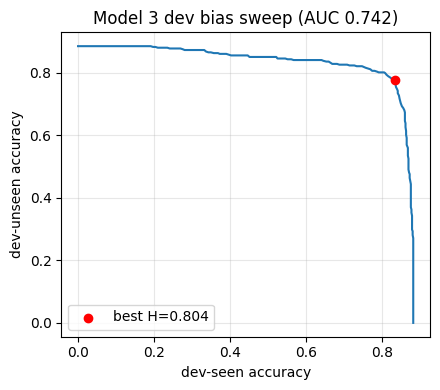

Dev complete: auto-switching to final for the next cell.


In [25]:
if CFG['run_mode'] != 'dev':
    print('Skipping dev run. Set CFG["run_mode"] = "dev" to calibrate.')
else:
    torch.cuda.empty_cache()
    dev_model, stage1_source = get_stage1(fit_df, 'dev')
    dev_model, s2_history, best = train_stage2(
        dev_model, fit_df, tag='dev',
        val_seen_df=val_seen_df, val_unseen_df=val_unseen_df,
    )

    best_path = OUT_DIR / 'stage2_dev_best.pt'
    if not best_path.exists():
        raise FileNotFoundError(f'No dev checkpoint written: {best_path}')
    best_ckpt = torch.load(best_path, map_location=DEVICE, weights_only=False)
    dev_model.load_state_dict(best_ckpt['model'])

    vs = run_inference(dev_model, make_loader(val_seen_df, eval_tf, CFG['eval_batch_size']))
    vu = run_inference(dev_model, make_loader(val_unseen_df, eval_tf, CFG['eval_batch_size']))
    S_dev, U_dev = comp_scores(vs), comp_scores(vu)
    sweep = bias_sweep(S_dev, vs['comp'], U_dev, vu['comp'])

    summary = dict(
        variant=VARIANT,
        stage1_source=stage1_source,
        stage1_epochs=CFG['stage1_epochs'],
        stage2_best_epoch=int(best_ckpt['epoch']),
        best_bias=float(sweep['best_bias']),
        val_best_hm=float(sweep['best_hm']),
        val_seen_at_best=float(sweep['best_seen']),
        val_unseen_at_best=float(sweep['best_novel']),
        val_auc=float(sweep['auc']),
        holdout_pairs=[COMP_NAMES[c] for c in HOLDOUT],
        data_fingerprint=data_fingerprint,
        cfg={k: str(v) if isinstance(v, Path) else v for k, v in CFG.items()},
    )
    with open(DEV_SUMMARY, 'w') as f:
        json.dump(summary, f, indent=2)
    print(json.dumps({k: v for k, v in summary.items() if k != 'cfg'}, indent=2))

    plt.figure(figsize=(4.5, 4))
    plt.plot(sweep['seen'], sweep['novel'], '-')
    plt.scatter([sweep['best_seen']], [sweep['best_novel']], c='r', zorder=3,
                label=f'best H={sweep["best_hm"]:.3f}')
    plt.xlabel('dev-seen accuracy')
    plt.ylabel('dev-unseen accuracy')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.title(f'Model 3 dev bias sweep (AUC {sweep["auc"]:.3f})')
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'dev_bias_curve.png', dpi=150)
    plt.show()

    if CFG['auto_final'] and not CFG['smoke']:
        CFG['run_mode'] = 'final'
        print('Dev complete: auto-switching to final for the next cell.', flush=True)

## Final run and test evaluation

This is the final, reportable run. It reads `runs/dev_summary.json` and takes the Stage 2
epoch count and the bias that dev selected. It trains Stage 1 on all 8,000 training
images, starting from Baseline 2 ViT's final model, then trains Stage 2 for the selected
number of epochs. No test image or test label is used for training or
calibration.

**A fix over Model 2:** when `auto_final` switches modes after the dev cell, the split
cell's dev values are still in memory. Those are `fit_df` and `NOVEL_MASK`, which marks
the 15 pseudo-unseen pairs as untrained. This cell resets both, so the bias is added only
to the 10 real unseen pairs and the shortcut rate uses all training pairs. Model 2's
final cell does not do this.

The table reports three rows:

1. **$b = 0$**: no calibration, the raw seen/unseen trade-off.
2. **Dev bias (REPORTED)**: the headline result.
3. **Test oracle**: the best bias on the test set; an upper bound only.

It also saves `runs/metrics.json` in Model 2's format (with `dev_bias`), the test bias
curve, and **`runs/model3_eval.pt`** for `evaluate_baselines.ipynb`. The team table
should use the numbers from that evaluator, so every model is scored by the same code.

[stage1:final] starting weights: /content/drive/MyDrive/COS30082/outputs/baseline2_multitask_vit/final/best.pt
[stage1:final] loaded /content/drive/MyDrive/COS30082/outputs/model3_supcon_partial_unfreeze/runs/stage1_final.pt (variant model3_supcon_partial_unfreeze, epoch 10)
[stage2] trainable: heads 0.18M + backbone 14.18M (blocks 10-11 + final norm)
[stage2:final] starting 8 epochs on 8000 images


stage2:final 1/8:   0%|          | 0/500 [00:00<?, ?it/s]

[stage2:final] epoch 01/8 | CE 2.7182


stage2:final 2/8:   0%|          | 0/500 [00:00<?, ?it/s]

[stage2:final] epoch 02/8 | CE 2.0048


stage2:final 3/8:   0%|          | 0/500 [00:00<?, ?it/s]

... (11 outputs left out)

,bias,seen top-1,seen top-5,unseen top-1,unseen top-5,harmonic mean
b = 0 (no calibration),0.000000,68.65%,88.95%,4.90%,23.55%,9.15%
b from dev validation (REPORTED),5.324000,64.70%,86.20%,41.09%,92.20%,50.26%
oracle b on test (upper bound),6.362000,57.60%,84.55%,55.11%,94.54%,56.33%


seen/unseen AUC: 0.4556


,crop acc,disease acc,crop+disease acc
test-seen,91.25%,70.55%,67.80%
test-unseen,69.68%,9.81%,3.31%


paper-protocol harmonic mean: 6.32%
shortcut rate: 64.70%


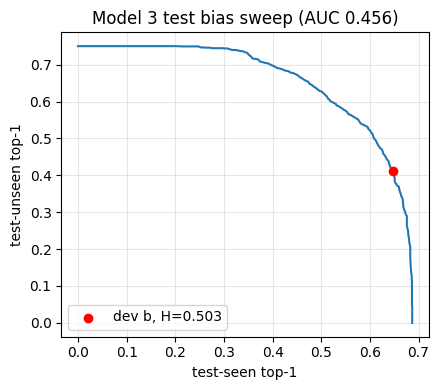

saved model3_eval.pt for evaluate_baselines.ipynb (154 tensors, bias 5.324)
saved: ['cm_crop_seen.png', 'cm_crop_unseen.png', 'cm_disease_seen.png', 'cm_disease_unseen.png', 'comparison_vs_baseline2.csv', 'dev_bias_curve.png', 'dev_summary.json', 'history_stage1_dev.csv', 'history_stage1_final.csv', 'history_stage2_dev.csv', 'history_stage2_final.csv', 'metrics.json', 'model3_eval.pt', 'score_distribution.png', 'stage1_dev.pt', 'stage1_final.pt', 'stage2_dev_best.pt', 'stage2_dev_last.pt', 'stage2_final_last.pt', 'test_bias_curve.png', 'topk_summary.png', 'training_curves_final.png', 'tsne_test_domains.png']

Add this entry to MODELS in evaluate_baselines.ipynb (adjust the folder to where you copy the two files):
    _spec(
        "model3_supcon_partial_unfreeze",
        "Model 3: factorized SupCon + partial unfreezing",
        "ViT-B/16",
        "multi-task",
        "vit",
        "multitask_vit",
        Path("model3") / "model3_eval.pt",
        Path("model3") / "metrics.json",

In [26]:
if CFG['run_mode'] != 'final':
    print('Skipping final run. Set CFG["run_mode"] = "final" after reviewing dev_summary.json.')
else:
    if not DEV_SUMMARY.exists():
        raise FileNotFoundError(f'Missing dev summary: {DEV_SUMMARY}. Run dev mode first.')
    dev = json.load(open(DEV_SUMMARY))
    stage2_epochs = max(1, int(dev['stage2_best_epoch']))
    dev_bias = float(dev['best_bias'])

    # Model 3 fix: after auto_final, fit_df and NOVEL_MASK still hold the dev split. Final trains on all
    # 8,000 images, so only the 10 real unseen pairs are novel.
    fit_df = train_df.copy()
    NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
    NOVEL_MASK[sorted(set(train_df['comp']))] = False
    assert int(NOVEL_MASK.sum()) == len(UNSEEN_COMPS), 'final evaluation must treat only the real unseen pairs as novel'

    torch.cuda.empty_cache()
    final_model, stage1_source_final = get_stage1(train_df, 'final')
    final_model, s2_history, _ = train_stage2(
        final_model, train_df, tag='final', epochs=stage2_epochs, known_bias=dev_bias,
    )

    final_ckpt = torch.load(OUT_DIR / 'stage2_final_last.pt', map_location=DEVICE, weights_only=False)
    final_model.load_state_dict(final_ckpt['model'])

    ts = run_inference(final_model, make_loader(test_seen_df, eval_tf, CFG['eval_batch_size']))
    tu = run_inference(final_model, make_loader(test_unseen_df, eval_tf, CFG['eval_batch_size']))
    S_test, U_test = comp_scores(ts), comp_scores(tu)
    test_sweep = bias_sweep(S_test, ts['comp'], U_test, tu['comp'])

    def report(bias):
        s1 = topk_acc(S_test, ts['comp'], 1, bias)
        u1 = topk_acc(U_test, tu['comp'], 1, bias)
        return {
            'bias': round(float(bias), 3),
            'seen top-1': s1,
            'seen top-5': topk_acc(S_test, ts['comp'], 5, bias),
            'unseen top-1': u1,
            'unseen top-5': topk_acc(U_test, tu['comp'], 5, bias),
            'harmonic mean': harmonic_mean(s1, u1),
        }

    results = pd.DataFrame({
        'b = 0 (no calibration)': report(0.0),
        'b from dev validation (REPORTED)': report(dev_bias),
        'oracle b on test (upper bound)': report(test_sweep['best_bias']),
    }).T
    display(results.style.format({c: '{:.2%}' for c in results.columns if c != 'bias'}))
    print(f"seen/unseen AUC: {test_sweep['auc']:.4f}")

    head_table = pd.DataFrame({
        'test-seen': paper_protocol(ts),
        'test-unseen': paper_protocol(tu),
    }).T
    display(head_table.style.format('{:.2%}'))
    paper_hm = harmonic_mean(
        head_table.at['test-seen', 'crop+disease acc'],
        head_table.at['test-unseen', 'crop+disease acc'],
    )
    shortcut = shortcut_rate(tu)
    print(f'paper-protocol harmonic mean: {paper_hm:.2%}')
    print(f'shortcut rate: {shortcut:.2%}')

    plt.figure(figsize=(4.5, 4))
    plt.plot(test_sweep['seen'], test_sweep['novel'], '-')
    r = report(dev_bias)
    plt.scatter([r['seen top-1']], [r['unseen top-1']], c='r', zorder=3,
                label=f'dev b, H={r["harmonic mean"]:.3f}')
    plt.xlabel('test-seen top-1')
    plt.ylabel('test-unseen top-1')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.title(f'Model 3 test bias sweep (AUC {test_sweep["auc"]:.3f})')
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'test_bias_curve.png', dpi=150)
    plt.show()

    results_dict = {
        name: {k: (float(v) if isinstance(v, (float, int, np.floating, np.integer)) else v)
               for k, v in row.items()}
        for name, row in results.iterrows()
    }
    heads_dict = {
        split: {k: float(v) for k, v in row.items()}
        for split, row in head_table.iterrows()
    }
    metrics = dict(
        variant=VARIANT,
        stage1_source=stage1_source_final,
        epochs=stage2_epochs,
        stage1_epochs=CFG['stage1_epochs'],
        stage2_epochs=stage2_epochs,
        dev_bias=dev_bias,
        results=results_dict,
        auc=float(test_sweep['auc']),
        heads=heads_dict,
        paper_protocol_hm=float(paper_hm),
        shortcut_rate=float(shortcut),
        data_fingerprint=data_fingerprint,
        cfg={k: str(v) if isinstance(v, Path) else v for k, v in CFG.items()},
    )
    with open(OUT_DIR / 'metrics.json', 'w') as f:
        json.dump(metrics, f, indent=2)
    export_for_team_evaluator(final_model, OUT_DIR / 'model3_eval.pt', stage2_epochs, dev_bias)
    print('saved:', sorted(p.name for p in OUT_DIR.glob('*')))
    print('''
Add this entry to MODELS in evaluate_baselines.ipynb (adjust the folder to where you copy the two files):
    _spec(
        "model3_supcon_partial_unfreeze",
        "Model 3: factorized SupCon + partial unfreezing",
        "ViT-B/16",
        "multi-task",
        "vit",
        "multitask_vit",
        Path("model3") / "model3_eval.pt",
        Path("model3") / "metrics.json",
        8,
    ),''')

## Comparison with Baseline 2 ViT

Baseline 2 ViT is the base model the team's deep-learning models start from, so this
cell shows how much Model 3 improves or degrades it. This follows Lawrence's Model 5.
Both models are scored here by the same functions, with the same evaluation transform, on
the same test images. Each uses **its own dev bias**, chosen on the same 15 pseudo-unseen
pairs, so neither sees test labels. Baseline 2's bias is read from its `dev/summary.json`.

The **change** column is Model 3 minus Baseline 2. For accuracies it is in percentage
points; a positive value is an improvement, except for the shortcut rate, where lower is
better. The table is saved to `runs/comparison_vs_baseline2.csv`. Use the team
evaluator's numbers for the report table, and this table to explain where Model 3 gains
or loses.

In [27]:
if CFG['run_mode'] != 'final':
    print('Skipping the Baseline 2 comparison (final mode only).')
else:
    class Baseline2ViT(nn.Module):
        """Baseline 2 ViT as its notebook saves it: one timm ViT-B/16 backbone with crop and disease heads."""
        def __init__(self):
            super().__init__()
            self.backbone = timm.create_model(CFG['backbone'], pretrained=False, num_classes=0)
            d = self.backbone.num_features
            self.dropout = nn.Dropout(0.2)          # inactive in eval mode; kept so the keys match
            self.crop_head = nn.Linear(d, NUM_CROPS)
            self.disease_head = nn.Linear(d, NUM_DISEASES)

        def forward(self, x):
            feat = self.backbone(x)
            return self.crop_head(feat), self.disease_head(feat), feat

    def b2_dev_bias():
        dev_path = Path(b2_checkpoint('dev', check_split=False))   # the split was checked in the dev run
        summary = dev_path.parent / 'summary.json'
        if summary.exists():
            return float(json.load(open(summary))['best_bias'])
        return float(torch.load(dev_path, map_location='cpu', weights_only=False)['bias'])

    def summarize(out_s, out_u, bias):
        S, U = comp_scores(out_s), comp_scores(out_u)
        sweep = bias_sweep(S, out_s['comp'], U, out_u['comp'])
        s1, u1 = topk_acc(S, out_s['comp'], 1, bias), topk_acc(U, out_u['comp'], 1, bias)
        s0, u0 = topk_acc(S, out_s['comp'], 1, 0.0), topk_acc(U, out_u['comp'], 1, 0.0)
        heads_u = paper_protocol(out_u)
        return {
            'bias b (from its dev run)': bias,
            'seen top-1': s1,
            'seen top-5': topk_acc(S, out_s['comp'], 5, bias),
            'unseen top-1': u1,
            'unseen top-5': topk_acc(U, out_u['comp'], 5, bias),
            'harmonic mean': harmonic_mean(s1, u1),
            'seen top-1 at b = 0': s0,
            'harmonic mean at b = 0': harmonic_mean(s0, u0),
            'best-possible harmonic mean (oracle b)': sweep['best_hm'],
            'seen/unseen AUC': sweep['auc'],
            'unseen crop accuracy': heads_u['crop acc'],
            'unseen disease accuracy': heads_u['disease acc'],
            'shortcut rate (lower is better)': shortcut_rate(out_u),
        }

    try:
        b2_bias = b2_dev_bias()
        b2_final_path = b2_checkpoint('final')
        b2 = Baseline2ViT()
        b2_ck = torch.load(b2_final_path, map_location='cpu', weights_only=False)
        b2.load_state_dict(b2_ck.get('model', b2_ck))   # strict: the keys must match Baseline 2 ViT exactly
    except (FileNotFoundError, KeyError, RuntimeError) as e:   # never lose a finished run over the comparison
        print('Skipping the Baseline 2 comparison:', e)
    else:
        b2 = b2.to(DEVICE)
        b2_ts = run_inference(b2, make_loader(test_seen_df, eval_tf, CFG['eval_batch_size']))
        b2_tu = run_inference(b2, make_loader(test_unseen_df, eval_tf, CFG['eval_batch_size']))
        del b2
        torch.cuda.empty_cache()

        comparison = pd.DataFrame({
            'Baseline 2 ViT': summarize(b2_ts, b2_tu, b2_bias),
            'Model 3': summarize(ts, tu, dev_bias),
        })
        comparison['change'] = comparison['Model 3'] - comparison['Baseline 2 ViT']
        comparison.to_csv(OUT_DIR / 'comparison_vs_baseline2.csv')

        raw_rows = ('bias b (from its dev run)', 'seen/unseen AUC')
        shown = comparison.copy().astype(object)
        for row in comparison.index:
            for col in comparison.columns:
                v = comparison.at[row, col]
                if row in raw_rows:
                    shown.at[row, col] = f'{v:+.3f}' if col == 'change' else f'{v:.3f}'
                else:
                    shown.at[row, col] = f'{100 * v:+.2f} pp' if col == 'change' else f'{v:.2%}'
        display(shown)
        print(f'Baseline 2 ViT weights: {b2_final_path} | its dev bias: {b2_bias:.3f}')
        print('saved', OUT_DIR / 'comparison_vs_baseline2.csv')

,Baseline 2 ViT,Model 3,change
bias b (from its dev run),4.995,5.324,+0.329
seen top-1,66.40%,64.70%,-1.70 pp
seen top-5,89.90%,86.20%,-3.70 pp
unseen top-1,51.59%,41.09%,-10.50 pp
unseen top-5,93.65%,92.20%,-1.45 pp
harmonic mean,58.06%,50.26%,-7.80 pp
seen top-1 at b = 0,71.40%,68.65%,-2.75 pp
harmonic mean at b = 0,9.78%,9.15%,-0.63 pp
best-possible harmonic mean (oracle b),63.84%,56.33%,-7.51 pp
seen/unseen AUC,0.540,0.456,-0.085


Baseline 2 ViT weights: /content/drive/MyDrive/COS30082/outputs/baseline2_multitask_vit/final/best.pt | its dev bias: 4.995
saved /content/drive/MyDrive/COS30082/outputs/model3_supcon_partial_unfreeze/runs/comparison_vs_baseline2.csv


## Visual diagnostics

The final evaluation cell already saves the seen–unseen bias curve. This cell
adds the diagnostics needed to explain *why* Model 3 behaves the way it does:

- **Training curves** — Stage-1 total/crop/disease SupCon loss and Stage-2
  cross-entropy + head accuracy. Flat or diverging curves are a signal to check
  the learning rate or batch size.
- **Test bias sweep** — the full seen/unseen trade-off; the red point is the
  dev-selected operating point.
- **Confusion matrices** — row-normalized crop and disease matrices for
  test-seen and test-unseen. The diagonal is per-class recall; off-diagonal mass
  shows which classes are confused.
- **Composition-score distributions** — seen vs unseen maximum scores at $b=0$.
  More overlap means the novelty bias has to do more work.
- **Top-1 / top-5 bars** — a compact summary of the $b=0$ and dev-bias operating
  points.
- **t-SNE of backbone features** — a qualitative 2-D view of test-seen vs
  test-unseen features. Separation here is descriptive, not a metric; t-SNE
  distances should not be over-interpreted.

These plots are saved at 150 DPI under `runs/`. They are diagnostic aids; the
reportable numbers remain the dev-bias row in `metrics.json`.

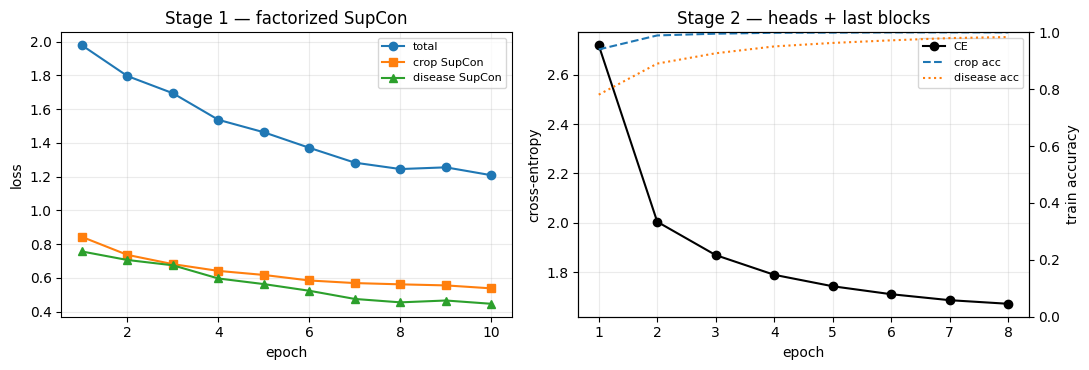

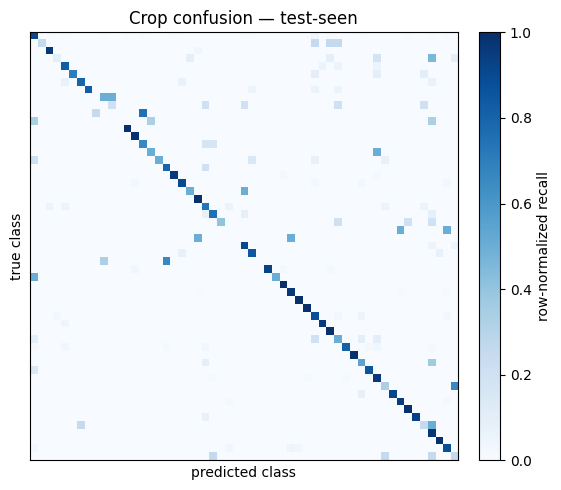

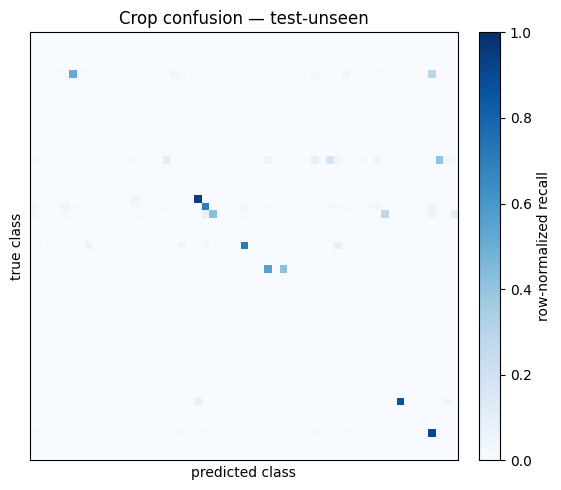

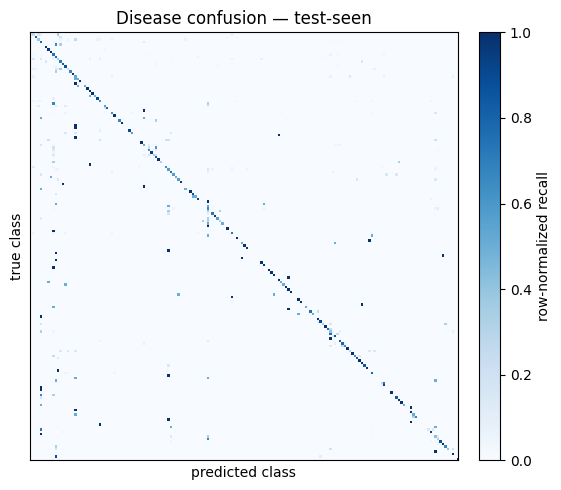

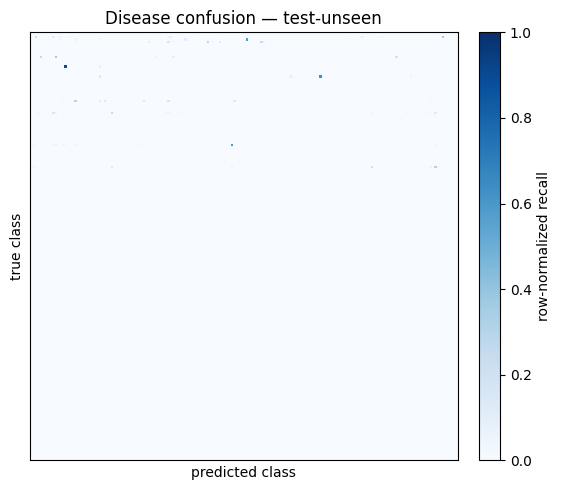

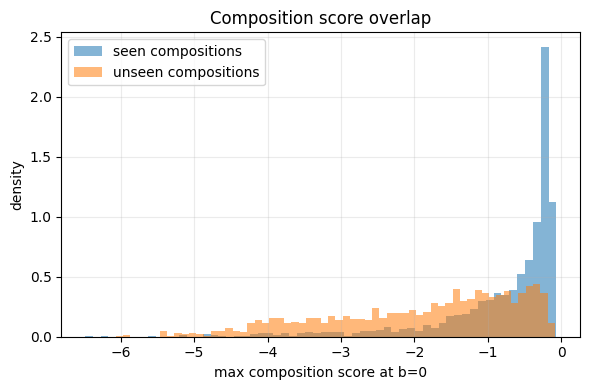

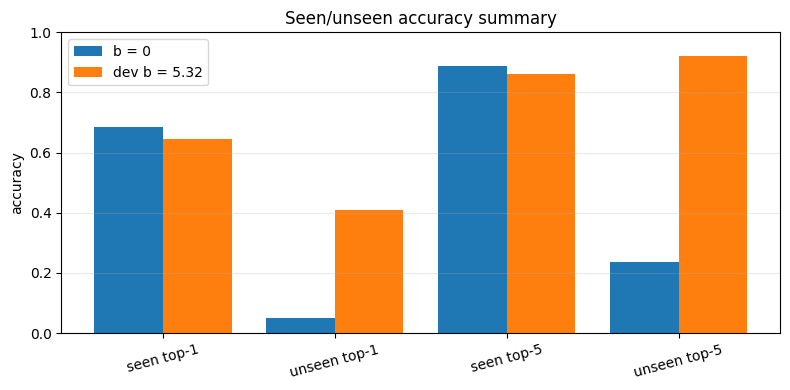

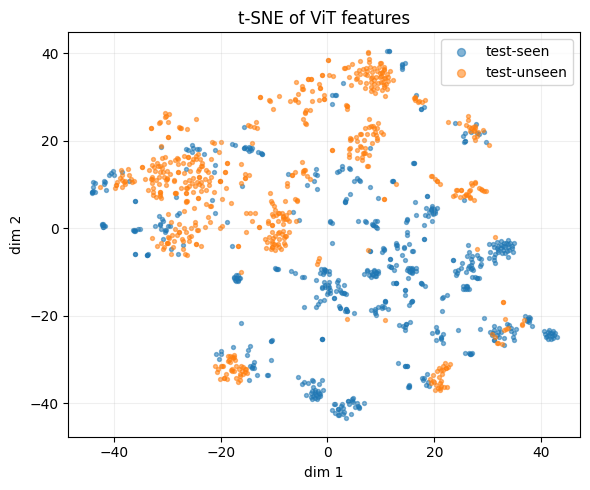

saved diagnostics: ['cm_crop_seen.png', 'cm_crop_unseen.png', 'cm_disease_seen.png', 'cm_disease_unseen.png', 'dev_bias_curve.png', 'score_distribution.png', 'test_bias_curve.png', 'topk_summary.png', 'training_curves_final.png', 'tsne_test_domains.png']


In [28]:
if CFG['run_mode'] != 'final':
    print('Skipping visual diagnostics. Set CFG["run_mode"] = "final" after dev calibration.')
else:
    import matplotlib.pyplot as plt
    from sklearn.manifold import TSNE

    ckpt_path = OUT_DIR / 'stage2_final_last.pt'
    if not ckpt_path.exists():
        raise FileNotFoundError(f'Missing final checkpoint: {ckpt_path}. Run the final cell first.')

    if 'final_model' in globals() and 'ts' in globals() and 'tu' in globals():
        diag_model, ts, tu = final_model, ts, tu
    else:
        diag_ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        diag_model = build_model()
        diag_model.load_state_dict(diag_ckpt['model'])
        ts = run_inference(diag_model, make_loader(test_seen_df, eval_tf, CFG['eval_batch_size']))
        tu = run_inference(diag_model, make_loader(test_unseen_df, eval_tf, CFG['eval_batch_size']))

    dev = json.load(open(DEV_SUMMARY))
    dev_bias = float(dev['best_bias'])
    S, U = comp_scores(ts), comp_scores(tu)
    test_sweep = bias_sweep(S, ts['comp'], U, tu['comp'])

    def _report(bias):
        s1 = topk_acc(S, ts['comp'], 1, bias)
        u1 = topk_acc(U, tu['comp'], 1, bias)
        return dict(
            seen_top1=s1,
            unseen_top1=u1,
            seen_top5=topk_acc(S, ts['comp'], 5, bias),
            unseen_top5=topk_acc(U, tu['comp'], 5, bias),
            hm=harmonic_mean(s1, u1),
        )

    # 1) Training curves
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    s1_path, s2_path = OUT_DIR / 'history_stage1_final.csv', OUT_DIR / 'history_stage2_final.csv'
    if s1_path.exists():
        h1 = pd.read_csv(s1_path)
        axes[0].plot(h1['epoch'], h1['train_loss'], marker='o', label='total')
        axes[0].plot(h1['epoch'], h1['crop_supcon'], marker='s', label='crop SupCon')
        axes[0].plot(h1['epoch'], h1['disease_supcon'], marker='^', label='disease SupCon')
        axes[0].set_xlabel('epoch')
        axes[0].set_ylabel('loss')
        axes[0].set_title('Stage 1 — factorized SupCon')
        axes[0].legend(fontsize=8)
        axes[0].grid(alpha=0.25)
    if s2_path.exists():
        h2 = pd.read_csv(s2_path)
        ax2 = axes[1]
        ax2.plot(h2['epoch'], h2['train_loss'], marker='o', color='black', label='CE')
        ax2.set_xlabel('epoch')
        ax2.set_ylabel('cross-entropy')
        ax2.set_title('Stage 2 — heads + last blocks')
        ax2.grid(alpha=0.25)
        ax3 = ax2.twinx()
        ax3.plot(h2['epoch'], h2['train_crop_acc'], '--', label='crop acc')
        ax3.plot(h2['epoch'], h2['train_disease_acc'], ':', label='disease acc')
        ax3.set_ylabel('train accuracy')
        ax3.set_ylim(0, 1)
        lines1, labels1 = ax2.get_legend_handles_labels()
        lines2, labels2 = ax3.get_legend_handles_labels()
        ax2.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='best')
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'training_curves_final.png', dpi=150)
    plt.show()
    plt.close(fig)

    # 2) Confusion matrices
    def _cm(y_true, y_pred, n):
        cm = np.zeros((n, n), dtype=np.float32)
        np.add.at(cm, (y_true.numpy(), y_pred.numpy()), 1.0)
        row = cm.sum(1, keepdims=True)
        row[row == 0] = 1.0
        return cm / row

    def _plot_cm(cm, title, path):
        fig, ax = plt.subplots(figsize=(6, 5))
        im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(title)
        ax.set_xlabel('predicted class')
        ax.set_ylabel('true class')
        ax.set_xticks([])
        ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='row-normalized recall')
        fig.tight_layout()
        fig.savefig(path, dpi=150)
        plt.show()
        plt.close(fig)

    pc_s, pd_s = ts['crop_lp'].argmax(1), ts['dis_lp'].argmax(1)
    pc_u, pd_u = tu['crop_lp'].argmax(1), tu['dis_lp'].argmax(1)
    _plot_cm(_cm(ts['crop'], pc_s, NUM_CROPS), 'Crop confusion — test-seen', OUT_DIR / 'cm_crop_seen.png')
    _plot_cm(_cm(tu['crop'], pc_u, NUM_CROPS), 'Crop confusion — test-unseen', OUT_DIR / 'cm_crop_unseen.png')
    _plot_cm(_cm(ts['disease'], pd_s, NUM_DISEASES), 'Disease confusion — test-seen', OUT_DIR / 'cm_disease_seen.png')
    _plot_cm(_cm(tu['disease'], pd_u, NUM_DISEASES), 'Disease confusion — test-unseen', OUT_DIR / 'cm_disease_unseen.png')

    # 3) Score distributions
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(S.max(1).values.numpy(), bins=60, alpha=0.55, density=True, label='seen compositions')
    ax.hist(U.max(1).values.numpy(), bins=60, alpha=0.55, density=True, label='unseen compositions')
    ax.set_xlabel('max composition score at b=0')
    ax.set_ylabel('density')
    ax.set_title('Composition score overlap')
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'score_distribution.png', dpi=150)
    plt.show()
    plt.close(fig)

    # 4) Top-1 / top-5 bars
    r0, rb = _report(0.0), _report(dev_bias)
    metrics_names = ['seen top-1', 'unseen top-1', 'seen top-5', 'unseen top-5']
    vals0 = [r0['seen_top1'], r0['unseen_top1'], r0['seen_top5'], r0['unseen_top5']]
    valsb = [rb['seen_top1'], rb['unseen_top1'], rb['seen_top5'], rb['unseen_top5']]
    x = np.arange(len(metrics_names))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(x - 0.2, vals0, width=0.4, label='b = 0')
    ax.bar(x + 0.2, valsb, width=0.4, label=f'dev b = {dev_bias:.2f}')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_names, rotation=15)
    ax.set_ylim(0, 1)
    ax.set_ylabel('accuracy')
    ax.set_title('Seen/unseen accuracy summary')
    ax.legend()
    ax.grid(axis='y', alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'topk_summary.png', dpi=150)
    plt.show()
    plt.close(fig)

    # 5) t-SNE of backbone features (qualitative)
    n = min(600, len(ts['feat']), len(tu['feat']))
    rng = np.random.default_rng(42)
    idx_s = rng.choice(len(ts['feat']), n, replace=False)
    idx_u = rng.choice(len(tu['feat']), n, replace=False)
    X = np.vstack([ts['feat'][idx_s].numpy(), tu['feat'][idx_u].numpy()])
    X = (X - X.mean(0, keepdims=True)) / (X.std(0, keepdims=True) + 1e-6)
    emb = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto',
               random_state=42).fit_transform(X)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(emb[:n, 0], emb[:n, 1], s=8, alpha=0.55, label='test-seen')
    ax.scatter(emb[n:, 0], emb[n:, 1], s=8, alpha=0.55, label='test-unseen')
    ax.set_title('t-SNE of ViT features')
    ax.set_xlabel('dim 1')
    ax.set_ylabel('dim 2')
    ax.legend(markerscale=2)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'tsne_test_domains.png', dpi=150)
    plt.show()
    plt.close(fig)

    print('saved diagnostics:', sorted(p.name for p in OUT_DIR.glob('*.png')))

## Reporting notes

- **Primary comparison: Model 3 vs Baseline 2 ViT,** the model it starts from. That is
  the comparison every team member makes. Use `runs/comparison_vs_baseline2.csv` to
  describe where Model 3 gains or loses on seen and unseen pairs. State the starting
  weights; they are recorded as `stage1_source` in `dev_summary.json` and `metrics.json`.
- **Model 3 vs Model 2** is an ablation of partial unfreezing. It is controlled only if
  both started Stage 1 from the same weights.
- **Expected effect:** higher seen top-1 at $b = 0$ and a higher calibrated harmonic mean.
  The hypothesis fails if unseen disease accuracy, the shortcut rate or AUC get worse.
  Report whichever happens: "partial unfreezing helps seen accuracy but costs unseen
  generalisation" is still a useful finding.
- **Use the team evaluator's numbers** (`evaluate_baselines.ipynb` with `model3_eval.pt`)
  in the report table, so Model 3 is scored by the same code as the baselines and the
  other SupCon models. That evaluator resizes ViT inputs with bicubic interpolation,
  while Model 2 and Model 3 train and self-evaluate with bilinear. Small differences from
  this notebook's table are expected.
- **The dev bias row is the headline;** the oracle row is an upper bound only. The t-SNE
  plot is qualitative.
- Pair the final table with `runs/test_bias_curve.png`, `runs/cm_disease_unseen.png`,
  `runs/score_distribution.png` and `runs/training_curves_final.png`.